In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("QuickCart Stockout Risk Project Started!")

QuickCart Stockout Risk Project Started!


In [ ]:
stores = pd.read_csv("/content/dim_stores.csv")
skus = pd.read_csv("/content/dim_skus.csv")

suppliers = pd.read_csv(
    "/content/dim_suppliers.csv",
    na_values=["N/A", "missing", "--", "NA", "null"]
)

events = pd.read_csv("/content/dim_events.csv")
fact = pd.read_csv("/content/fact_inventory_daily.csv")

print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Inventory:", fact.shape)

Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Inventory: (21600, 16)


In [ ]:
# Check the stockout risk distribution
print("Target Class Counts:")
print(fact["stockout_risk"].value_counts())

print("\nTarget Class Percentages:")
print(
    (fact["stockout_risk"].value_counts(normalize=True) * 100)
    .round(2)
)

Target Class Counts:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Target Class Percentages:
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64


In [ ]:
print("Duplicate inventory rows:", fact.duplicated().sum())

print("\nMissing values in inventory:")
print(fact.isnull().sum())

print("\nSupplier reliability values:")
print(suppliers["reliability_score"])

Duplicate inventory rows: 0

Missing values in inventory:
date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
dtype: int64

Supplier reliability values:
0     0.92
1     0.93
2     0.90
3     0.70
4     0.66
5      NaN
6     0.67
7     0.73
8     0.72
9     0.66
10    0.83
11    0.63
12    0.91
13     NaN
14     NaN
Name: reliability_score, dtype: float64


In [ ]:
# 1. Standardize city display names
stores["city_display"] = stores["city_display"].str.title()

# 2. Convert supplier reliability to numeric
suppliers["reliability_score"] = pd.to_numeric(
    suppliers["reliability_score"],
    errors="coerce"
)

# 3. Fill missing reliability with the median
median_reliability = suppliers["reliability_score"].median()

suppliers["reliability_score"] = (
    suppliers["reliability_score"].fillna(median_reliability)
)

# 4. Convert dates to datetime format
fact["date"] = pd.to_datetime(fact["date"])
events["date"] = pd.to_datetime(events["date"])

# 5. Verify cleaning
print("Missing supplier reliability:",
      suppliers["reliability_score"].isna().sum())

print("\nStandardized city names:")
print(stores[["city", "city_display"]])

print("\nDate range:")
print(fact["date"].min(), "to", fact["date"].max())

Missing supplier reliability: 0

Standardized city names:
         city city_display
0      Mumbai       Mumbai
1      Mumbai       Mumbai
2   Bengaluru    Bengaluru
3   Bengaluru    Bengaluru
4       Delhi        Delhi
5       Delhi        Delhi
6        Pune         Pune
7        Pune         Pune
8   Hyderabad    Hyderabad
9   Hyderabad    Hyderabad
10    Chennai      Chennai
11    Chennai      Chennai

Date range:
2026-10-01 00:00:00 to 2026-10-30 00:00:00


In [ ]:
# Join inventory with store information
df = fact.merge(
    stores,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# Join product information
df = df.merge(
    skus,
    on=["sku_id", "supplier_id"],
    how="left",
    validate="many_to_one"
)

# Join supplier information
df = df.merge(
    suppliers,
    on="supplier_id",
    how="left",
    validate="many_to_one"
)

# Join festival and promotion information
df = df.merge(
    events,
    on="date",
    how="left",
    validate="many_to_one"
)

print("Joined dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Joined dataset shape: (21600, 39)

Columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

First five rows:


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,popularity_tier,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


In [ ]:
# Count each stockout risk category
risk_counts = df["stockout_risk"].value_counts()

print("Stockout Risk Counts:")
display(risk_counts.to_frame("Number of Records"))

print("\nStockout Risk Percentages:")
display(
    (df["stockout_risk"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Stockout Risk Counts:


,Number of Records
stockout_risk,
Safe,14131
At-Risk,5186
Imminent,2283



Stockout Risk Percentages:


,Percentage
stockout_risk,
Safe,65.42
At-Risk,24.01
Imminent,10.57


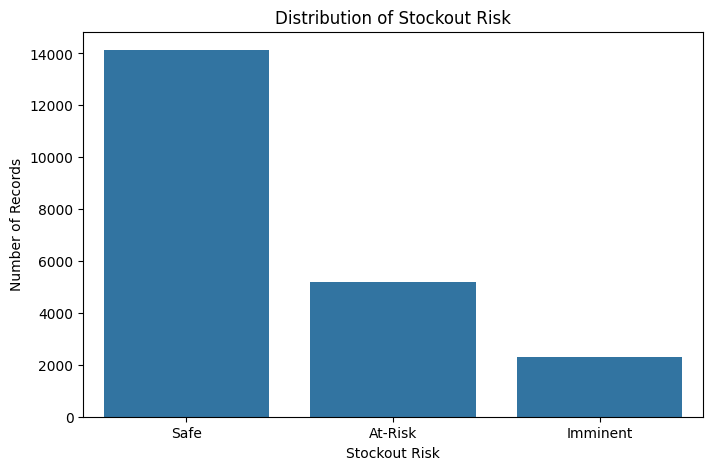

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="stockout_risk",
    order=["Safe", "At-Risk", "Imminent"]
)

plt.title("Distribution of Stockout Risk")
plt.xlabel("Stockout Risk")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
festival_analysis = (
    df.groupby("is_festival_week")["stockout_risk"]
    .apply(lambda x: (x == "Imminent").mean() * 100)
    .round(2)
)

print("Imminent Stockout Rate by Festival Status:")
display(festival_analysis.to_frame("Imminent Rate (%)"))

Imminent Stockout Rate by Festival Status:


,Imminent Rate (%)
is_festival_week,
N,9.51
Y,23.31


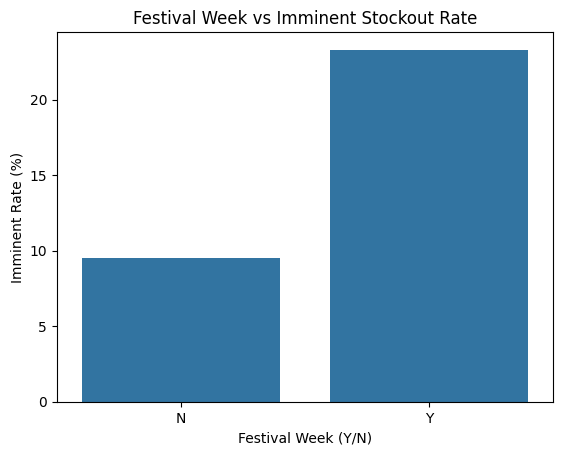

In [ ]:
festival_plot = (
    df.assign(
        imminent=(df["stockout_risk"] == "Imminent").astype(int)
    )
    .groupby("is_festival_week")["imminent"]
    .mean()
    .mul(100)
    .reset_index()
)

sns.barplot(
    data=festival_plot,
    x="is_festival_week",
    y="imminent"
)

plt.title("Festival Week vs Imminent Stockout Rate")
plt.xlabel("Festival Week (Y/N)")
plt.ylabel("Imminent Rate (%)")
plt.show()

In [ ]:
df["reliability_group"] = pd.cut(
    df["reliability_score"],
    bins=[-float("inf"), 0.75, 0.85, float("inf")],
    labels=["Low", "Mid", "High"],
    right=False
)

supplier_analysis = (
    df.assign(
        imminent=df["stockout_risk"].eq("Imminent")
    )
    .groupby("reliability_group", observed=False)["imminent"]
    .mean()
    .mul(100)
    .round(2)
)

print("Imminent Rate by Supplier Reliability:")
display(supplier_analysis.to_frame("Imminent Rate (%)"))

Imminent Rate by Supplier Reliability:


,Imminent Rate (%)
reliability_group,
Low,13.07
Mid,3.26
High,3.82


In [ ]:
# Check unique supplier reliability scores
print("Supplier reliability scores:")
display(
    suppliers[["supplier_id", "reliability_score"]]
    .sort_values("reliability_score")
)

# Count records and Imminent cases in each group
verification = df.groupby(
    "reliability_group",
    observed=False
).agg(
    total_records=("stockout_risk", "size"),
    imminent_records=(
        "stockout_risk",
        lambda x: (x == "Imminent").sum()
    )
)

verification["imminent_rate_pct"] = (
    verification["imminent_records"]
    / verification["total_records"] * 100
).round(2)

display(verification)

Supplier reliability scores:


,supplier_id,reliability_score
11,SUP12,0.630
4,SUP05,0.660
9,SUP10,0.660
6,SUP07,0.670
3,SUP04,0.700
8,SUP09,0.720
13,SUP14,0.725
5,SUP06,0.725
14,SUP15,0.725
7,SUP08,0.730


,total_records,imminent_records,imminent_rate_pct
reliability_group,,,
Low,15840,2071,13.07
Mid,1440,47,3.26
High,4320,165,3.82


In [ ]:
# Feature engineering

# 1. Difference between reorder point and closing stock
df["reorder_gap"] = (
    df["reorder_point"] - df["closing_stock"]
)

# 2. Days of cover relative to expected supplier lead time
df["days_of_cover_ratio"] = (
    df["days_of_cover"] /
    df["lead_time_days_expected"].replace(0, np.nan)
)

# 3. Extract day of month
df["day_of_month"] = df["date"].dt.day

# 4. Days since Diwali week started (October 22, 2026)
festival_start = pd.Timestamp("2026-10-22")

df["days_since_festival_start"] = (
    df["date"] - festival_start
).dt.days.clip(lower=0)

# 5. Convert Yes/No-style fields into numeric indicators
for col in ["is_perishable", "festive_relevant", "is_festival_week"]:
    df[col + "_flag"] = (
        df[col].astype(str).str.strip().str.upper().isin(["Y", "YES"])
    ).astype(int)

# Display the engineered features
display(
    df[
        [
            "date",
            "sku_id",
            "reorder_gap",
            "days_of_cover_ratio",
            "day_of_month",
            "days_since_festival_start",
            "is_perishable_flag",
            "festive_relevant_flag",
            "is_festival_week_flag",
        ]
    ].head()
)

,date,sku_id,reorder_gap,days_of_cover_ratio,day_of_month,days_since_festival_start,is_perishable_flag,festive_relevant_flag,is_festival_week_flag
0,2026-10-01,SKU001,-108.5,9.66,1,0,1,0,0
1,2026-10-02,SKU001,-98.5,10.79,2,0,1,0,0
2,2026-10-03,SKU001,-83.5,8.99,3,0,1,0,0
3,2026-10-04,SKU001,-73.5,8.79,4,0,1,0,0
4,2026-10-05,SKU001,-64.5,8.55,5,0,1,0,0


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Sort data chronologically
df = df.sort_values("date").copy()

# Select features available in the joined dataset
numeric_features = [
    "opening_stock",
    "units_demanded",
    "units_sold",
    "closing_stock",
    "reorder_point",
    "lead_time_days_expected",
    "sales_velocity_7d",
    "days_of_cover",
    "reorder_gap",
    "days_of_cover_ratio",
    "day_of_month",
    "days_since_festival_start",
    "is_perishable_flag",
    "festive_relevant_flag",
    "is_festival_week_flag",
    "unit_price_inr",
    "shelf_life_days",
    "reliability_score",
    "base_lead_time_days",
    "lead_time_variance_days",
    "demand_multiplier_festive",
    "demand_multiplier_other"
]

categorical_features = [
    "category",
    "store_size",
    "popularity_tier",
    "event_type"
]

features = numeric_features + categorical_features
target = "stockout_risk"

# Time-based split
train_mask = df["date"] < "2026-10-24"
test_mask = df["date"] >= "2026-10-24"

X_train = df.loc[train_mask, features]
X_test = df.loc[test_mask, features]

y_train = df.loc[train_mask, target]
y_test = df.loc[test_mask, target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining dates:",
      df.loc[train_mask, "date"].min(),
      "to",
      df.loc[train_mask, "date"].max())

print("\nTesting dates:",
      df.loc[test_mask, "date"].min(),
      "to",
      df.loc[test_mask, "date"].max())


Training rows: 16560
Testing rows: 5040

Training dates: 2026-10-01 00:00:00 to 2026-10-23 00:00:00

Testing dates: 2026-10-24 00:00:00 to 2026-10-30 00:00:00


In [ ]:

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Define the models
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Train and evaluate each model
results = []

for name, model in models.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print(f"Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test,
        y_pred,
        labels=["Safe", "At-Risk", "Imminent"]
    ))

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

# Compare overall accuracy
results_df = pd.DataFrame(results)
display(results_df.sort_values("Accuracy", ascending=False))



Baseline
Accuracy: 0.6228

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.00      0.00      0.00      1126
    Imminent       0.00      0.00      0.00       775
        Safe       0.62      1.00      0.77      3139

    accuracy                           0.62      5040
   macro avg       0.21      0.33      0.26      5040
weighted avg       0.39      0.62      0.48      5040

Confusion Matrix:
[[3139    0    0]
 [1126    0    0]
 [ 775    0    0]]

Logistic Regression
Accuracy: 0.8196

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.97      0.20      0.34      1126
    Imminent       0.49      1.00      0.66       775
        Safe       0.97      1.00      0.98      3139

    accuracy                           0.82      5040
   macro avg       0.81      0.73      0.66      5040
weighted avg       0.90      0.82      0.79      5040

Confusion Matrix:
[[3129    4    6]
 [  93  230  803

,Model,Accuracy
2,Random Forest,0.930159
1,Logistic Regression,0.819643
0,Baseline,0.622817


In [ ]:

# Give more weight to Imminent stockout cases
rf_tuned = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight={
            "Safe": 1,
            "At-Risk": 1,
            "Imminent": 3
        },
        random_state=42,
        n_jobs=-1
    ))
])

# Train the tuned model
rf_tuned.fit(X_train, y_train)

# Predict test data
y_pred_tuned = rf_tuned.predict(X_test)

# Evaluate results
print("Tuned Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=["At-Risk", "Imminent", "Safe"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["Safe", "At-Risk", "Imminent"]
))


Tuned Random Forest Accuracy: 0.9317

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.79      0.96      0.86      1126
    Imminent       0.91      0.63      0.74       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.93      5040
   macro avg       0.90      0.86      0.87      5040
weighted avg       0.94      0.93      0.93      5040


Confusion Matrix:
[[3134    5    0]
 [   2 1076   48]
 [   0  289  486]]


In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get class probabilities from the tuned model
rf_model = rf_tuned.named_steps["model"]
class_names = list(rf_model.classes_)

print("Model classes:", class_names)

# Find the Imminent probability column
imminent_index = class_names.index("Imminent")
probabilities = rf_tuned.predict_proba(X_test)

# Predict normally, then flag Imminent at a lower threshold
threshold = 0.35
y_pred_threshold = rf_tuned.predict(X_test).copy()

imminent_mask = probabilities[:, imminent_index] >= threshold
y_pred_threshold[imminent_mask] = "Imminent"

print("\nThreshold:", threshold)
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_threshold,
    labels=["At-Risk", "Imminent", "Safe"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_threshold,
    labels=["Safe", "At-Risk", "Imminent"]
))


Model classes: ['At-Risk', 'Imminent', 'Safe']

Threshold: 0.35

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.84      0.90      0.87      1126
    Imminent       0.84      0.76      0.80       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.94      5040
   macro avg       0.89      0.89      0.89      5040
weighted avg       0.94      0.94      0.94      5040


Confusion Matrix:
[[3134    5    0]
 [   2 1015  109]
 [   0  187  588]]


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score

probabilities = rf_tuned.predict_proba(X_test)
classes = list(rf_tuned.named_steps["model"].classes_)

imminent_index = classes.index("Imminent")
other_indices = [
    i for i, name in enumerate(classes)
    if name != "Imminent"
]

p_imminent = probabilities[:, imminent_index]

# Best alternative when a case is not classified as Imminent
other_predictions = np.array(classes)[
    np.argmax(probabilities[:, other_indices], axis=1)
]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45]:
    predictions = other_predictions.copy()
    predictions[p_imminent >= threshold] = "Imminent"

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Imminent Precision": round(
            precision_score(
                y_test, predictions,
                labels=["Imminent"],
                average="macro",
                zero_division=0
            ), 4
        ),
        "Imminent Recall": round(
            recall_score(
                y_test, predictions,
                labels=["Imminent"],
                average="macro",
                zero_division=0
            ), 4
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)


,Threshold,Accuracy,Imminent Precision,Imminent Recall
0,0.30,0.3210,0.1618,0.8155
1,0.35,0.3181,0.1534,0.7587
2,0.40,0.3153,0.1462,0.7123
3,0.45,0.3147,0.1408,0.6761


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score
import pandas as pd
import numpy as np

# Probabilities from the tuned Random Forest
probabilities = rf_tuned.predict_proba(X_test)
class_names = list(rf_tuned.named_steps["model"].classes_)
imminent_index = class_names.index("Imminent")

imminent_probs = probabilities[:, imminent_index]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    # Start with normal predictions
    predictions = rf_tuned.predict(X_test).copy()

    # Override predictions when imminent probability crosses threshold
    predictions[imminent_probs >= threshold] = "Imminent"

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Imminent Precision": precision_score(
            y_test, predictions,
            labels=["Imminent"],
            average="micro",
            zero_division=0
        ),
        "Imminent Recall": recall_score(
            y_test, predictions,
            labels=["Imminent"],
            average="micro",
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))


,Threshold,Accuracy,Imminent Precision,Imminent Recall
0,0.30,0.9429,0.8208,0.8155
1,0.35,0.9399,0.8436,0.7587
2,0.40,0.9371,0.8638,0.7123
3,0.45,0.9365,0.8942,0.6761
4,0.50,0.9325,0.9108,0.6323


In [ ]:

final_threshold = 0.30

final_predictions = rf_tuned.predict(X_test).copy()
final_predictions[imminent_probs >= final_threshold] = "Imminent"

print("Final Threshold:", final_threshold)

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    labels=["Safe", "At-Risk", "Imminent"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    final_predictions,
    labels=["Safe", "At-Risk", "Imminent"]
))


Final Threshold: 0.3

Classification Report:
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.87      0.88      0.87      1126
    Imminent       0.82      0.82      0.82       775

    accuracy                           0.94      5040
   macro avg       0.90      0.90      0.90      5040
weighted avg       0.94      0.94      0.94      5040


Confusion Matrix:
[[3134    5    0]
 [   2  986  138]
 [   0  143  632]]


In [ ]:

import joblib

# Save the trained model pipeline
joblib.dump(rf_tuned, "quickcart_stockout_model.pkl")

# Save the selected threshold
joblib.dump(final_threshold, "quickcart_threshold.pkl")

print("Model saved successfully!")
print("Threshold:", final_threshold)



Model saved successfully!
Threshold: 0.3


,Feature,Importance
9,num__days_of_cover_ratio,0.239820
8,num__reorder_gap,0.220847
7,num__days_of_cover,0.203509
3,num__closing_stock,0.061061
0,num__opening_stock,0.036939
6,num__sales_velocity_7d,0.029962
4,num__reorder_point,0.025370
17,num__reliability_score,0.022673
2,num__units_sold,0.019593
1,num__units_demanded,0.019548


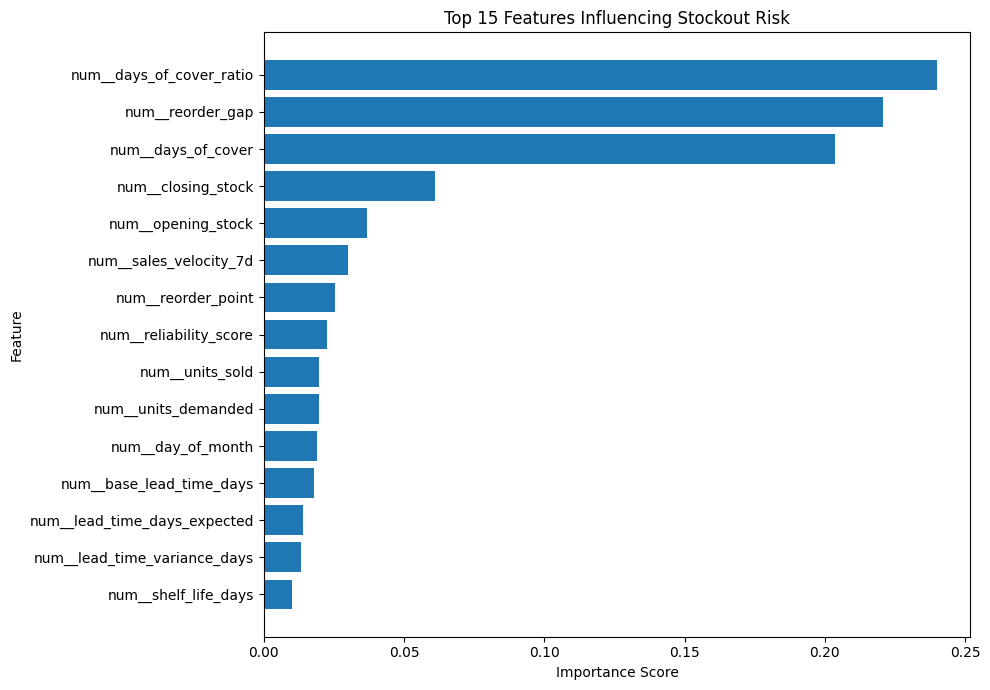

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest model
rf_model = rf_tuned.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    rf_tuned.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Display the top 15 features
importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

display(importance_df.head(15))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Stockout Risk")
plt.tight_layout()
plt.show()


In [ ]:

# Inspect stockout risk against key stock features

display(
    df.groupby("stockout_risk")[
        [
            "closing_stock",
            "reorder_point",
            "days_of_cover",
            "days_of_cover_ratio",
            "reorder_gap"
        ]
    ].agg(["mean", "median", "min", "max"]).round(2)
)


closing_stock                     reorder_point              \
                       mean median  min     max          mean median  min   
stockout_risk                                                               
At-Risk               74.32   45.8  1.0   651.9         85.12   56.3  3.0   
Imminent              34.73   15.2  0.0   418.4         75.48   50.5  3.0   
Safe                 159.54  102.3  3.6  1091.6         67.16   41.4  3.0   

                     days_of_cover                     days_of_cover_ratio  \
                 max          mean median  min     max                mean   
stockout_risk                                                                
At-Risk        467.4          4.05   3.82  1.0    8.80                1.66   
Imminent       422.1          1.95   1.72  0.0    7.88                0.68   
Safe           467.4         10.64  10.05  4.0  134.85                6.46   

                                   reorder_gap                       
              median   min     max        mean median    min    max  
stockout_risk                                                        
At-Risk         1.45  0.20    4.08       10.80    2.6 -230.2  344.7  
Imminent        0.60  0.00    3.66       40.75   21.8  -27.4  393.5  
Safe            4.97  0.81  134.85      -92.38  -55.3 -810.0   60.1

In [ ]:

# Check target distribution
print("Stockout risk distribution:")
print(df["stockout_risk"].value_counts())

print("\nPercentage distribution:")
print(
    df["stockout_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Check whether days of cover separates the classes
print("\nDays of cover by stockout risk:")
display(
    df.groupby("stockout_risk")["days_of_cover"]
    .agg(["count", "min", "median", "max"])
    .round(2)
    .sort_values("median")
)


Stockout risk distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Percentage distribution:
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64

Days of cover by stockout risk:


,count,min,median,max
stockout_risk,,,,
Imminent,2283,0.0,1.72,7.88
At-Risk,5186,1.0,3.82,8.80
Safe,14131,4.0,10.05,134.85


In [ ]:

# Test how much the model depends on the top 3 features

reduced_numeric_features = [
    col for col in numeric_features
    if col not in [
        "days_of_cover",
        "days_of_cover_ratio",
        "reorder_gap"
    ]
]

reduced_features = reduced_numeric_features + categorical_features

X_train_reduced = df.loc[train_mask, reduced_features]
X_test_reduced = df.loc[test_mask, reduced_features]

reduced_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, reduced_numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

reduced_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

reduced_model.fit(X_train_reduced, y_train)

reduced_pred = reduced_model.predict(X_test_reduced)

print("Reduced model accuracy:",
      round(accuracy_score(y_test, reduced_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    reduced_pred,
    labels=["Safe", "At-Risk", "Imminent"],
    zero_division=0
))


Reduced model accuracy: 0.8405

Classification report:
              precision    recall  f1-score   support

        Safe       0.88      0.99      0.93      3139
     At-Risk       0.67      0.59      0.63      1126
    Imminent       0.89      0.58      0.70       775

    accuracy                           0.84      5040
   macro avg       0.81      0.72      0.75      5040
weighted avg       0.84      0.84      0.83      5040



In [ ]:
risk_summary = df.groupby("stockout_risk")[
    ["days_of_cover", "days_of_cover_ratio", "reorder_gap"]
].agg(["mean", "median", "min", "max"])

display(risk_summary)

days_of_cover                     days_of_cover_ratio          \
                       mean median  min     max                mean  median   
stockout_risk                                                                 
At-Risk            4.051568   3.82  1.0    8.80            1.662209  1.4500   
Imminent           1.947157   1.72  0.0    7.88            0.675387  0.5975   
Safe              10.636469  10.05  4.0  134.85            6.459418  4.9700   

                             reorder_gap                       
                 min     max        mean median    min    max  
stockout_risk                                                  
At-Risk        0.204    4.08   10.797898    2.6 -230.2  344.7  
Imminent       0.000    3.66   40.750723   21.8  -27.4  393.5  
Safe           0.812  134.85  -92.379655  -55.3 -810.0   60.1

In [ ]:

# Check the target labels and related columns
print("Columns related to stock and risk:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["risk", "stockout", "cover", "lead_time"])
])

print("\nStockout risk counts:")
print(df["stockout_risk"].value_counts())

print("\nStockout risk percentages:")
print(
    (df["stockout_risk"].value_counts(normalize=True) * 100)
    .round(2)
)


Columns related to stock and risk:
['lead_time_days_expected', 'lead_time_days_actual', 'days_of_cover', 'stockout_risk', 'base_lead_time_days', 'lead_time_variance_days', 'days_of_cover_ratio']

Stockout risk counts:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Stockout risk percentages:
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64


# QuickCart Stockout Risk Prediction

## 1. Project Overview

The QuickCart Stockout Risk Prediction project uses supervised machine learning to classify inventory risk for products across multiple stores.

The project predicts three classes:

- **Safe:** Sufficient stock is available relative to replenishment time.
- **At-Risk:** Stock coverage is getting close to the expected replenishment time.
- **Imminent:** Stock may run out before the next delivery arrives.

The objective is to identify potentially critical inventory shortages early so that inventory teams can prioritize replenishment and reduce lost sales.